In [0]:
1import pandas as pd
import numpy as np

In [0]:
multi_class=spark.table("machinelearning.default.multi_class_beanchmark").toPandas()

display(multi_class)

sepal_length,sepal_width,petal_length,petal_width,species
5.1,3.5,1.4,0.2,setosa
4.9,3.0,1.4,0.2,setosa
4.7,3.2,1.3,0.2,setosa
4.6,3.1,1.5,0.2,setosa
5.0,3.6,1.4,0.2,setosa
5.4,3.9,1.7,0.4,setosa
4.6,3.4,1.4,0.3,setosa
5.0,3.4,1.5,0.2,setosa
4.4,2.9,1.4,0.2,setosa
4.9,3.1,1.5,0.1,setosa


In [0]:
# Check the number of rows and columns
multi_class.shape

(150, 5)

In [0]:
# Check the column names and data types
multi_class.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [0]:
# Check whether there are missing values
multi_class.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [0]:
# Check how many flowers belong to each species
multi_class['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [0]:
# Count how many flowers belong to each species
multi_class['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [0]:
# Check the unique species names
multi_class['species'].unique()

array(['setosa', 'versicolor', 'virginica'], dtype=object)

In [0]:
 # Get statistical information about numerical columns
multi_class.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [0]:
# Count duplicate rows
print("Number of duplicate rows:", multi_class.duplicated().sum())

Number of duplicate rows: 1


In [0]:
# Count missing values in each column
print(multi_class.isnull().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [0]:
# Count the number of flowers in each species
species_count = multi_class['species'].value_counts()

# Display the results
print(species_count)

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


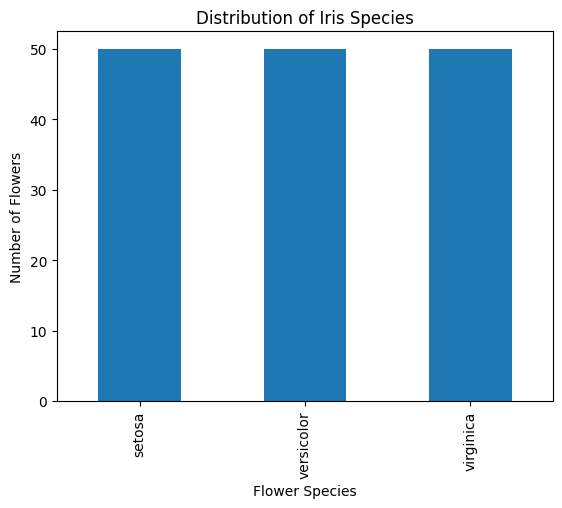

In [0]:
# Import the plotting library
import matplotlib.pyplot as plt

# Create a bar chart
species_count.plot(kind='bar')

# Add chart title and labels
plt.title('Distribution of Iris Species')
plt.xlabel('Flower Species')
plt.ylabel('Number of Flowers')

# Display the chart
plt.show()

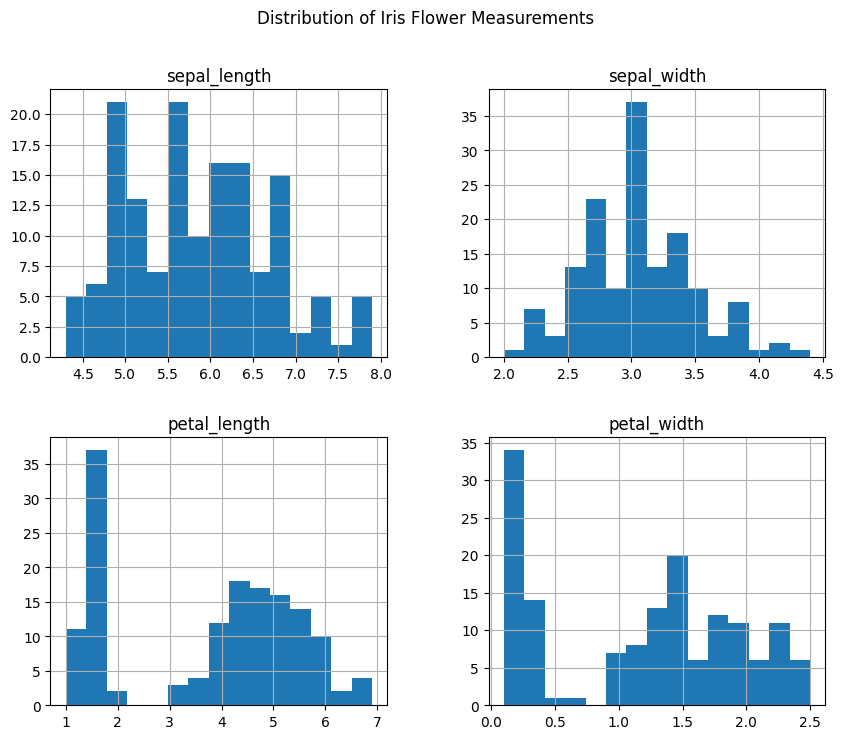

In [0]:
 # Create histograms for all numerical columns
multi_class.hist(figsize=(10, 8), bins=15)

# Add a heading
plt.suptitle('Distribution of Iris Flower Measurements')

# Display the graphs
plt.show()

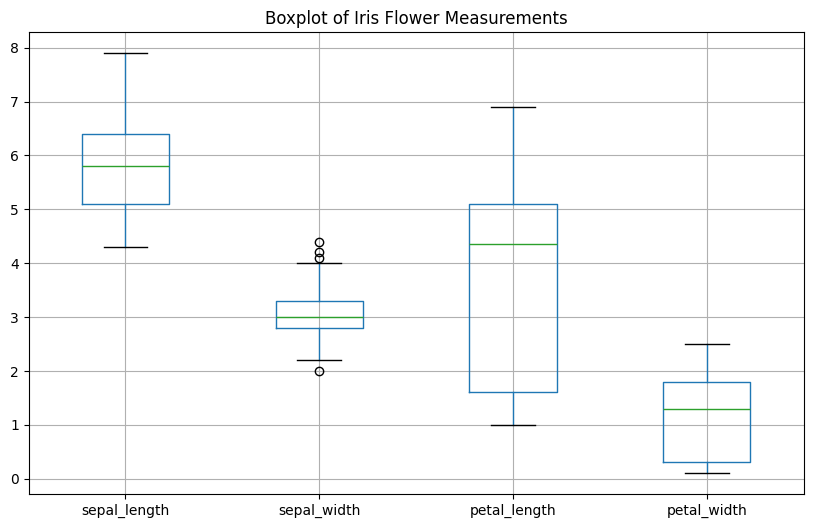

In [0]:
 # Create a figure
plt.figure(figsize=(10, 6))

# Create boxplots for numerical columns
multi_class.boxplot(column=[
    'sepal_length',
    'sepal_width',
    'petal_length',
    'petal_width'
])

# Add title
plt.title('Boxplot of Iris Flower Measurements')

# Display the graph
plt.show()

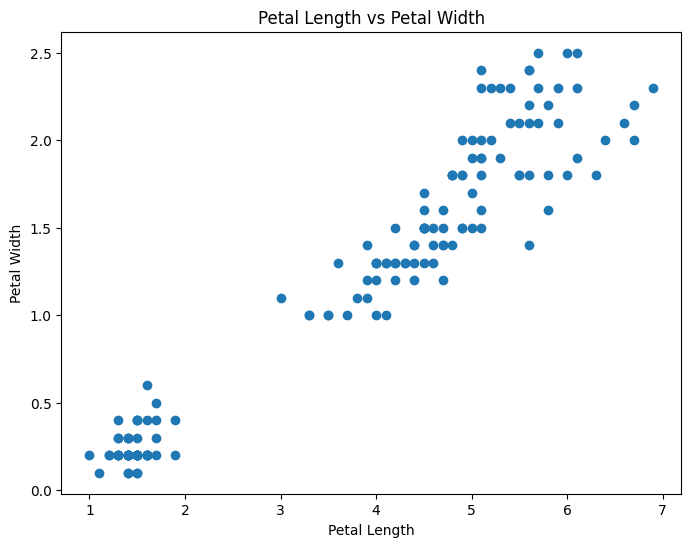

In [0]:
 # Create a scatter plot
plt.figure(figsize=(8, 6))

# Compare petal length and petal width
plt.scatter(
    multi_class['petal_length'],
    multi_class['petal_width']
)

# Add title and labels
plt.title('Petal Length vs Petal Width')
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')

# Display graph
plt.show()

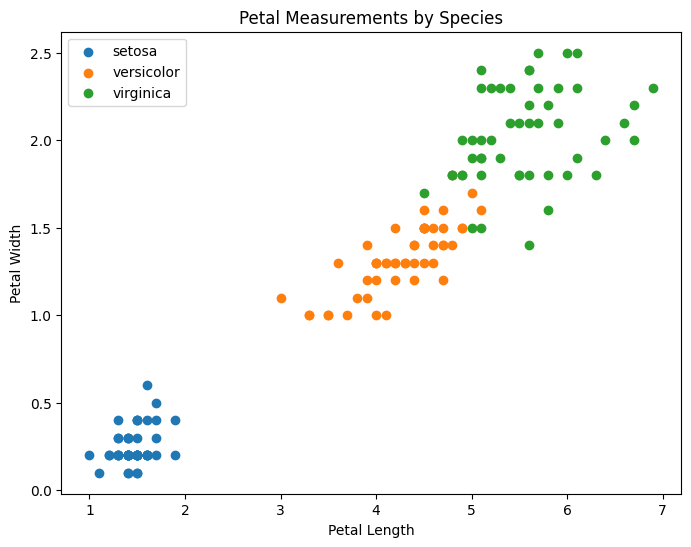

In [0]:
 # Create a scatter plot for different species
plt.figure(figsize=(8, 6))

for species in multi_class['species'].unique():
    species_data = multi_class[multi_class['species'] == species]

    plt.scatter(
        species_data['petal_length'],
        species_data['petal_width'],
        label=species
    )

# Add title and labels
plt.title('Petal Measurements by Species')
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')

# Display legend
plt.legend()

plt.show()

Correlation analysis

In [0]:
 # Calculate correlation between numerical columns
correlation = multi_class.select_dtypes(include='number').corr()

# Display correlation values
print(correlation)

              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.117570      0.871754     0.817941
sepal_width      -0.117570     1.000000     -0.428440    -0.366126
petal_length      0.871754    -0.428440      1.000000     0.962865
petal_width       0.817941    -0.366126      0.962865     1.000000


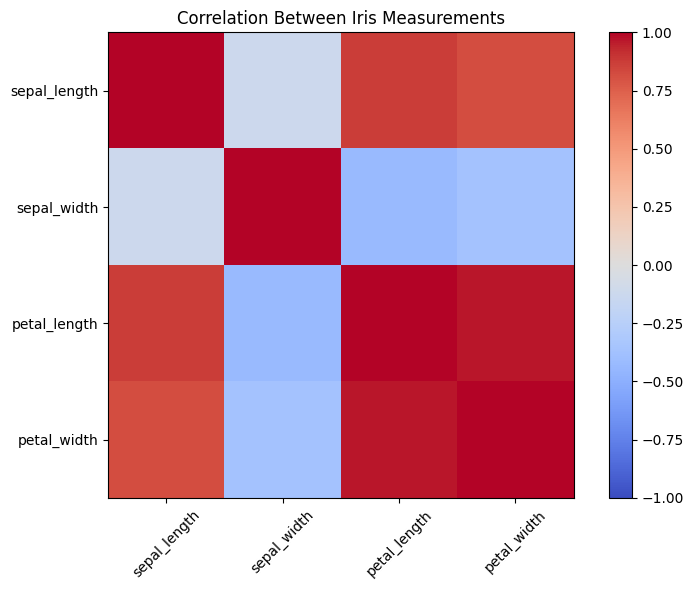

In [0]:
 # Create a figure
plt.figure(figsize=(8, 6))

# Display correlation as an image
plt.imshow(correlation, cmap='coolwarm', vmin=-1, vmax=1)

# Add colour scale
plt.colorbar()

# Add column names
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)), correlation.columns)

# Add title
plt.title('Correlation Between Iris Measurements')

plt.tight_layout()
plt.show()

In [0]:
# X contains the flower measurements
X = multi_class[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]

# y contains the species we want to predict
y = multi_class['species']

In [0]:
print(X.head())
print(y.head())

   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [0]:
# Import train_test_split
from sklearn.model_selection import train_test_split

# Divide our data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
) 

In [0]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(120, 4)
(30, 4)
(120,)
(30,)


In [0]:
# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

In [0]:
# Create our decision tree model
model = DecisionTreeClassifier(random_state=42)

In [0]:
# Teach the model using our training data
model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [0]:
 # Use our trained model to predict the species
y_pred = model.predict(X_test)

# Display the predicted species
print(y_pred)

['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [0]:
# Create a table to compare actual and predicted species
comparison = pd.DataFrame({
    'Actual Species': y_test.values,
    'Predicted Species': y_pred
})

# Display the comparison
display(comparison)

Actual Species,Predicted Species
setosa,setosa
virginica,virginica
versicolor,versicolor
versicolor,versicolor
setosa,setosa
versicolor,versicolor
setosa,setosa
setosa,setosa
virginica,virginica
versicolor,versicolor


In [0]:
 # Calculate average measurements for each species
species_average = multi_class.groupby('species').mean()

# Display the results
display(species_average)

sepal_length,sepal_width,petal_length,petal_width
5.006,3.428,1.462,0.24600000000000002
5.936,2.77,4.26,1.3259999999999998
6.587999999999999,2.9739999999999998,5.5520000000000005,2.026


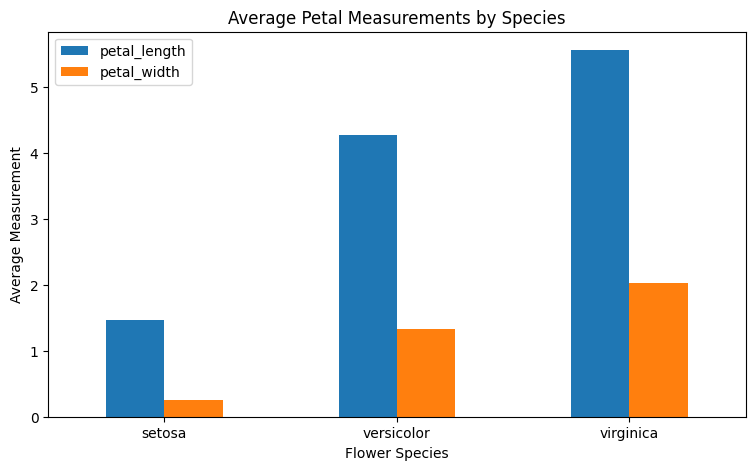

In [0]:
 # Plot average petal measurements
species_average[['petal_length', 'petal_width']].plot(kind='bar', figsize=(9, 5))

# Add title and labels
plt.title('Average Petal Measurements by Species')
plt.xlabel('Flower Species')
plt.ylabel('Average Measurement')

# Display graph
plt.xticks(rotation=0)
plt.show()

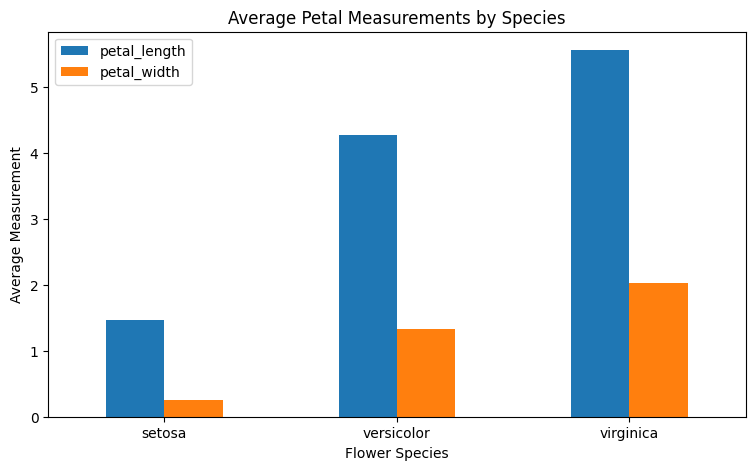

In [0]:
 # Plot average petal measurements by species
species_average[['petal_length', 'petal_width']].plot(
    kind='bar',
    figsize=(9, 5)
)

# Add chart title and labels
plt.title('Average Petal Measurements by Species')
plt.xlabel('Flower Species')
plt.ylabel('Average Measurement')

# Display chart
plt.xticks(rotation=0)
plt.show()

In [0]:
# Check the number of records per species
print(multi_class['species'].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [0]:
 # Select the four input features
X = multi_class[['sepal_length', 'sepal_width',
                 'petal_length', 'petal_width']]

# Select the target column
y = multi_class['species']

In [0]:
 # Import train_test_split
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training target: (120,)
Testing target: (30,)


In [0]:
 # Import the Decision Tree model
from sklearn.tree import DecisionTreeClassifier

# Create the model
decision_tree = DecisionTreeClassifier(random_state=42)

# Train the model using the training data
decision_tree.fit(X_train, y_train)

# Ask the model to predict the species of the test flowers
y_pred_tree = decision_tree.predict(X_test)

# Display the predictions
print(y_pred_tree)

['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


Import evaluation tools

In [0]:
# Import tools to evaluate our model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

Calculate accuracy

- What does accuracy mean?

Accuracy tells us how many flowers the model classified correctly out of the 30 test flowers.

For example, an accuracy of 0.95 means the model correctly classified 95% of the flowers.

In [0]:
# Compare the actual answers with the model's predictions
y_pred = decision_tree.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

# Display the accuracy
print("Decision Tree Accuracy:", accuracy)

Decision Tree Accuracy: 0.9333333333333333


Check precision, recall and F1-score

What are we checking?
- Precision: When the model predicts a species, how often is it correct?
- Recall: Out of all actual flowers of a species, how many did the model identify correctly?
- F1-score: A combined measure of precision and recall.
- Support: How many actual flowers belong to each species in the test data.

In [0]:
# Show precision, recall and F1-score for each flower species
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Confusion Matrix

1. Setosa
- Precision = 1.00: Every flower predicted as setosa was correct.
- Recall = 1.00: The model found all 10 actual setosa flowers.
- F1-score = 1.00: Perfect result for this species.
2. Versicolor
- Precision = 0.90: 90% of the model's versicolor predictions were correct.
- Recall = 0.90: It correctly identified 9 out of 10 actual versicolor flowers.
- F1-score = 0.90: Very good performance.
3. Virginica
- Precision = 0.90: 90% of the model's virginica predictions were correct.
- Recall = 0.90: It correctly identified 9 out of 10 actual virginica flowers.
- F1-score = 0.90: Very good performance.

In [0]:
# Create a confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
print(cm)

[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


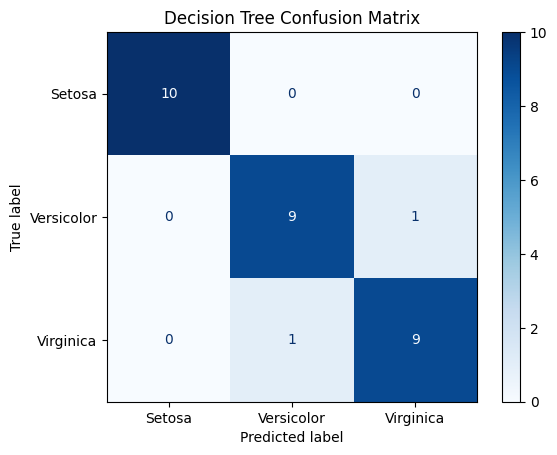

In [0]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Display the confusion matrix as a graph
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Setosa', 'Versicolor', 'Virginica']
)

# Draw the graph
display_cm.plot(cmap='Blues')

# Add a title
plt.title('Decision Tree Confusion Matrix')

# Display the graph
plt.show()

Model 2: Logistic Regression
Step 1: What is Logistic Regression?
Logistic Regression is a machine learning algorithm used for classification.

In our Iris case study, it will learn from the flower measurements and predict which of the three species a flower belongs to:
- Setosa
- Versicolor
- Virginica
Unlike Decision Tree, Logistic Regression works by calculating probabilities for each species and choosing the most likely one.
Step 2: Prepare the data (scaling)
Logistic Regression works better when numerical features are on a similar scale.

For example:
- Sepal length ranges from approximately 4.3 to 7.9.
- Petal length ranges from approximately 1.0 to 6.9.

We use StandardScaler to put the measurements on a comparable scale.

In [0]:
 # Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn the scaling from the training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to the testing data
X_test_scaled = scaler.transform(X_test)

Build the Logistic Regression model

In [0]:
 # Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = LogisticRegression(max_iter=200)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test_scaled)

Check accuracy

In [0]:
 # Calculate accuracy
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

# Display accuracy
print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.9333333333333333


Check precision, recall and F1-score

In [0]:
 # Display the classification report
print(classification_report(y_test, y_pred_logistic))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



Check the confusion matrix

In [0]:
 # Create the confusion matrix
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

# Display the results
print(cm_logistic)

[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [0]:
 # Import Random Forest
from sklearn.ensemble import RandomForestClassifier

In [0]:
 # Create the Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model using our training data
random_forest.fit(X_train, y_train)

# Make predictions using the testing data
y_pred_forest = random_forest.predict(X_test)

In [0]:
 # Calculate accuracy
forest_accuracy = accuracy_score(y_test, y_pred_forest)

# Display accuracy
print("Random Forest Accuracy:", forest_accuracy)

Random Forest Accuracy: 0.9


In [0]:
 # Display the classification report
print(classification_report(y_test, y_pred_forest))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [0]:
 # Create the confusion matrix
cm_forest = confusion_matrix(y_test, y_pred_forest)

# Display the confusion matrix
print(cm_forest)

[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


In [0]:
 # Display the classification report
print(classification_report(y_test, y_pred_forest))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [0]:
 # Display the classification report
print(classification_report(y_test, y_pred_forest))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



Model Evaluation

In [0]:
 # Import pandas
import pandas as pd

# Create a table to compare our three models
model_comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Logistic Regression', 'Random Forest'],

    'Accuracy': [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_forest)
    ],

    'Precision': [
        0.93, 0.93, 0.90
    ],

    'Recall': [
        0.93, 0.93, 0.90
    ],

    'F1-score': [
        0.93, 0.93, 0.90
    ]
})

# Display the comparison table
display(model_comparison)

Model,Accuracy,Precision,Recall,F1-score
Decision Tree,0.9333333333333333,0.93,0.93,0.93
Logistic Regression,0.9333333333333333,0.93,0.93,0.93
Random Forest,0.9,0.9,0.9,0.9


Evaluate ROC-AUC

In [0]:
 # Import the ROC-AUC evaluation tool
from sklearn.metrics import roc_auc_score

# Get probability predictions from each model
tree_prob = decision_tree.predict_proba(X_test)

logistic_prob = logistic_model.predict_proba(X_test_scaled)

forest_prob = random_forest.predict_proba(X_test)

# Calculate ROC-AUC for each model
print("Decision Tree ROC-AUC:",
      roc_auc_score(y_test, tree_prob, multi_class='ovr'))

print("Logistic Regression ROC-AUC:",
      roc_auc_score(y_test, logistic_prob, multi_class='ovr'))

print("Random Forest ROC-AUC:",
      roc_auc_score(y_test, forest_prob, multi_class='ovr'))

Decision Tree ROC-AUC: 0.9499999999999998
Logistic Regression ROC-AUC: 0.9966666666666667
Random Forest ROC-AUC: 0.9866666666666667


In [0]:
 # Import the tools needed for ROC curves
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Convert the actual species into binary values
y_test_binary = label_binarize(
    y_test,
    classes=['setosa', 'versicolor', 'virginica']
)

# Get predicted probabilities from each model
tree_prob = decision_tree.predict_proba(X_test)
logistic_prob = logistic_model.predict_proba(X_test_scaled)
forest_prob = random_forest.predict_proba(X_test)

# Calculate ROC curve for each model
tree_fpr, tree_tpr, _ = roc_curve(y_test_binary.ravel(), tree_prob.ravel())

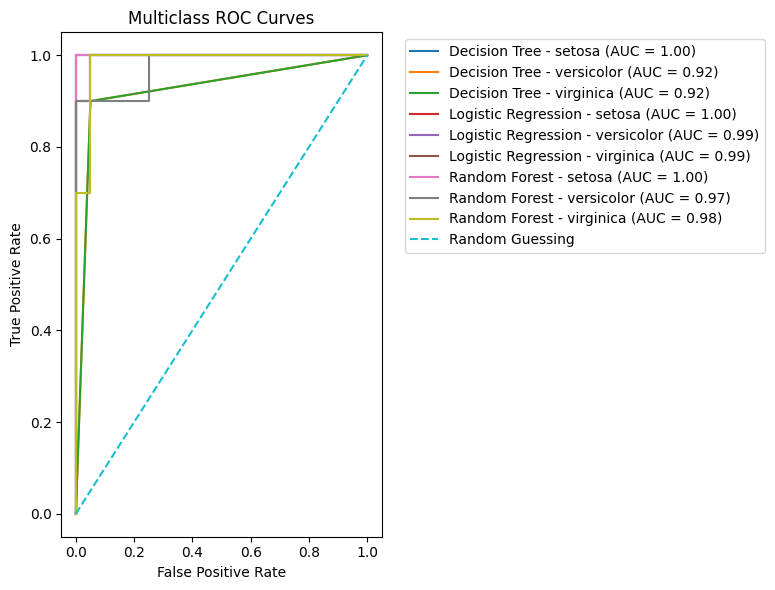

In [0]:
 # Create a list of our models and their probability predictions
models = {
    'Decision Tree': tree_prob,
    'Logistic Regression': logistic_prob,
    'Random Forest': forest_prob
}

# Create a graph
plt.figure(figsize=(8, 6))

# Draw one ROC curve for each model and each species
for model_name, probabilities in models.items():

    # Calculate the ROC curve for each species
    for i, species in enumerate(['setosa', 'versicolor', 'virginica']):

        fpr, tpr, thresholds = roc_curve(
            y_test_binary[:, i],
            probabilities[:, i]
        )

        # Calculate the AUC
        roc_auc = auc(fpr, tpr)

        # Draw the curve
        plt.plot(
            fpr,
            tpr,
            label=f'{model_name} - {species} (AUC = {roc_auc:.2f})'
        )

# Draw the random guessing line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guessing')

# Add graph labels
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multiclass ROC Curves')

# Show the legend
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

# Display the graph
plt.tight_layout()
plt.show()

In [0]:
 # Decision Tree training accuracy
tree_train_accuracy = accuracy_score(
    y_train,
    decision_tree.predict(X_train)
)

# Logistic Regression training accuracy
logistic_train_accuracy = accuracy_score(
    y_train,
    logistic_model.predict(X_train_scaled)
)

# Random Forest training accuracy
forest_train_accuracy = accuracy_score(
    y_train,
    random_forest.predict(X_train)
)

# Display the results
print("Decision Tree:")
print("Training:", tree_train_accuracy)
print("Testing:", accuracy_score(y_test, y_pred))

print("\nLogistic Regression:")
print("Training:", logistic_train_accuracy)
print("Testing:", accuracy_score(y_test, y_pred_logistic))

print("\nRandom Forest:")
print("Training:", forest_train_accuracy)
print("Testing:", accuracy_score(y_test, y_pred_forest))

Decision Tree:
Training: 1.0
Testing: 0.9333333333333333

Logistic Regression:
Training: 0.9583333333333334
Testing: 0.9333333333333333

Random Forest:
Training: 1.0
Testing: 0.9


cross-validation

- The training data is divided into 5 groups.
- The model trains on 4 groups.
- The remaining group is used for validation.
- This process repeats 5 times, with a different validation group each time.
- We calculate the average performance across all 5 round


In [0]:
 # Import cross-validation tools
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Import Pipeline to combine scaling and Logistic Regression
from sklearn.pipeline import Pipeline

In [0]:
 # Create 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

Evaluate Decision Tree

In [0]:
 # Evaluate Decision Tree using cross-validation
tree_scores = cross_val_score(
    decision_tree,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

# Display the results
print("Decision Tree scores:", tree_scores)
print("Decision Tree average:", tree_scores.mean())

Decision Tree scores: [0.95833333 0.95833333 0.95833333 0.95833333 0.91666667]
Decision Tree average: 0.95


In [0]:
 # Create a pipeline with scaling and Logistic Regression
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=200))
])

# Evaluate using 5-fold cross-validation
logistic_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

# Display the results
print("Logistic Regression scores:", logistic_scores)
print("Logistic Regression average:", logistic_scores.mean())

Logistic Regression scores: [0.95833333 1.         0.95833333 0.95833333 0.91666667]
Logistic Regression average: 0.9583333333333334


In [0]:
  # Create a pipeline with scaling and Logistic Regression
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=200))
])

# Evaluate using 5-fold cross-validation
logistic_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

# Display the results
print("Logistic Regression scores:", logistic_scores)
print("Logistic Regression average:", logistic_scores.mean())

Logistic Regression scores: [0.95833333 1.         0.95833333 0.95833333 0.91666667]
Logistic Regression average: 0.9583333333333334


In [0]:
 # Evaluate Random Forest using 5-fold cross-validation
forest_scores = cross_val_score(
    random_forest,
    X_train,
    y_train,
    cv=cv,
    scoring='accuracy'
)

# Display the five scores
print("Random Forest scores:", forest_scores)

# Calculate the average accuracy
print("Random Forest average:", forest_scores.mean())

Random Forest scores: [0.95833333 1.         0.95833333 0.91666667 0.91666667]
Random Forest average: 0.95


In [0]:
 # Show how important each flower measurement is
feature_importance = random_forest.feature_importances_

# Match each importance score to its feature name
for feature, importance in zip(X.columns, feature_importance):
    print(feature, ":", importance)

sepal_length : 0.11634850540739942
sepal_width : 0.014999733101994138
petal_length : 0.43146640568097017
petal_width : 0.4371853558096363
